# Exploration de la source OpenWeather

## 1. Contexte et objectif du notebook

Après OpenSky, je passe à la deuxième source du projet : OpenWeather, qui donne les conditions météorologiques actuelles pour un point géographique précis (`https://api.openweathermap.org/data/2.5/weather`), après avoir lu la documentation (`https://openweathermap.org/api/one-call-4?collection=one_call_api`).

La logique d'appel est différente de celle d'OpenSky. Là où OpenSky renvoyait en un seul appel tous les avions présents sur une zone entière, OpenWeather fonctionne point par point : impossible d'interroger toute l'Europe météorologiquement en un seul appel, il faut demander la météo aéroport par aéroport.

Le module d'ingestion météo boucle donc sur une liste fixe de dix hubs aéroportuaires européens (Paris CDG, Londres Heathrow, Francfort, Amsterdam, Madrid, Rome, Istanbul, Dublin, Munich, Barcelone) et effectue un appel par aéroport.

Je veux comprendre, comme pour OpenSky : combien de lignes cela représente, quelle est la fraîcheur des mesures, quels champs sont complets ou non, si les valeurs sont physiquement cohérentes, et quel volume cela représente sur la durée du projet.

Comme pour OpenSky, ces résultats ne sont pas figés : l'API renvoie les conditions météo au moment de la requête, donc relancer ce notebook plus tard donnera des valeurs différentes (température, vent, description du ciel...). Ce qui reste stable, c'est la structure des données et les règles de qualité identifiées ci-dessous.

In [1]:
import glob
import json
import os
import sys
import warnings
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import pandas as pd

# On se place à la racine du projet pour retrouver src/, config/ et le fichier .env
RACINE_PROJET = os.path.abspath(os.path.join(os.getcwd(), ".."))
if RACINE_PROJET not in sys.path:
    sys.path.insert(0, RACINE_PROJET)
os.chdir(RACINE_PROJET)

from src.ingestion.openweather_client import OpenWeatherClient
from src.utils.chemins import chemin_relatif_projet

pd.set_option("display.max_columns", None)

## 2. Récupération et chargement des données

J'interroge le module d'ingestion météo pour les dix hubs aéroportuaires définis dans `HUBS_AEROPORTUAIRES` : chaque appel renvoie la météo actuelle pour un seul aéroport, donc dix appels HTTP au total pour cette capture.

J'appelle l'API OpenWeather en direct, puis je sauvegarde le résultat dans `data/raw/` (fichier JSON horodaté, non versionné), comme pour OpenSky. En cas d'erreur (API indisponible, quota dépassé), je retombe sur le dernier fichier déjà collecté, pour que le notebook reste exécutable même hors connexion.

In [2]:
DOSSIER_DONNEES_BRUTES = os.path.join(RACINE_PROJET, "data", "raw")

try:
    client = OpenWeatherClient()
    donnees_brutes = client.recuperer_meteo_hubs_aeroportuaires()
    instant_collecte_utc = datetime.now(timezone.utc)
    chemin_fichier = client.sauvegarder_donnees_brutes(
        donnees_brutes, dossier=DOSSIER_DONNEES_BRUTES
    )
    print(f"Nouvel appel API réussi, données sauvegardées dans : {chemin_relatif_projet(chemin_fichier)}")
except Exception as erreur:
    print(f"Appel API impossible ({erreur}), réutilisation du dernier fichier disponible.")
    fichiers_disponibles = sorted(
        glob.glob(os.path.join(DOSSIER_DONNEES_BRUTES, "openweather_*.json"))
    )
    chemin_fichier = fichiers_disponibles[-1]
    instant_collecte_utc = datetime.fromtimestamp(
        os.path.getmtime(chemin_fichier), tz=timezone.utc
    )
    with open(chemin_fichier, encoding="utf-8") as fichier:
        donnees_brutes = json.load(fichier)
    print(f"Fichier réutilisé : {chemin_relatif_projet(chemin_fichier)}")

2026-08-25 16:47:56,715 - src.ingestion.openweather_client - INFO - Récupération de la météo pour Paris Charles-de-Gaulle (CDG).
2026-08-25 16:47:57,449 - src.ingestion.openweather_client - INFO - Appel à l'API OpenWeather réussi (code 200).
2026-08-25 16:47:57,455 - src.ingestion.openweather_client - INFO - Récupération de la météo pour Londres Heathrow (LHR).
2026-08-25 16:47:58,081 - src.ingestion.openweather_client - INFO - Appel à l'API OpenWeather réussi (code 200).
2026-08-25 16:47:58,085 - src.ingestion.openweather_client - INFO - Récupération de la météo pour Francfort (FRA).
2026-08-25 16:47:58,729 - src.ingestion.openweather_client - INFO - Appel à l'API OpenWeather réussi (code 200).
2026-08-25 16:47:58,733 - src.ingestion.openweather_client - INFO - Récupération de la météo pour Amsterdam Schiphol (AMS).
2026-08-25 16:47:59,430 - src.ingestion.openweather_client - INFO - Appel à l'API OpenWeather réussi (code 200).
2026-08-25 16:47:59,435 - src.ingestion.openweather_client

Nouvel appel API réussi, données sauvegardées dans : data/raw/openweather_20260825_164803.json


## 3. Combien de lignes obtient-on, et à quoi ressemblent les données une fois mises à plat ?

Chaque réponse d'OpenWeather est un objet JSON imbriqué (température et pression regroupées sous `main`, vent sous `wind`, etc.). Je mets chaque hub à plat en une seule ligne, avec les champs imbriqués renommés en notation pointée (`main.temp`, `wind.speed`...), pour obtenir un DataFrame directement exploitable.

In [3]:
lignes_meteo = []
for hub in donnees_brutes["hubs"]:
    ligne = pd.json_normalize(hub["meteo"]).iloc[0].to_dict()
    ligne["nom_aeroport"] = hub["nom_aeroport"]
    ligne["code_iata"] = hub["code_iata"]
    lignes_meteo.append(ligne)

df_meteo = pd.DataFrame(lignes_meteo)

colonnes_identification = ["nom_aeroport", "code_iata"]
colonnes_ordonnees = colonnes_identification + [
    colonne for colonne in df_meteo.columns if colonne not in colonnes_identification
]
df_meteo = df_meteo[colonnes_ordonnees]

print(f"Nombre de lignes (aéroports) : {len(df_meteo)}")
print(f"Nombre de colonnes : {df_meteo.shape[1]}")
df_meteo.head(10)

Nombre de lignes (aéroports) : 10
Nombre de colonnes : 30


,nom_aeroport,code_iata,weather,base,visibility,dt,timezone,id,name,cod,coord.lon,coord.lat,main.temp,main.feels_like,main.temp_min,main.temp_max,main.pressure,main.humidity,main.sea_level,main.grnd_level,wind.speed,wind.deg,clouds.all,sys.type,sys.id,sys.country,sys.sunrise,sys.sunset,rain.1h,wind.gust
0,Paris Charles-de-Gaulle,CDG,"[{'id': 800, 'main': 'Clear', 'description': '...",stations,10000,1787669276,7200,2983073,Roissy-en-France,200,2.5479,49.0097,27.87,27.69,26.36,29.17,1010,42,1010,1000,3.60,270,8,1,6542,FR,1787633773,1787683688,NaN,NaN
1,Londres Heathrow,LHR,"[{'id': 800, 'main': 'Clear', 'description': '...",stations,10000,1787669276,3600,7284876,Heathrow,200,-0.4543,51.4700,25.79,25.47,24.97,27.65,1012,40,1012,1007,7.72,110,6,1,1417,GB,1787634192,1787684709,NaN,NaN
2,Francfort,FRA,"[{'id': 500, 'main': 'Rain', 'description': 'l...",stations,10000,1787669277,7200,7290400,Airport Frankfurt Main,200,8.5622,50.0379,18.16,18.07,17.76,19.18,1015,78,1015,999,1.54,50,100,1,1265,DE,1787632206,1787682369,0.18,NaN
3,Amsterdam Schiphol,AMS,"[{'id': 804, 'main': 'Clouds', 'description': ...",stations,10000,1787669278,7200,2747542,Schiphol,200,4.7639,52.3086,24.99,24.69,23.84,26.10,1014,44,1014,1014,5.66,70,96,1,1524,NL,1787632828,1787683569,NaN,NaN
4,Madrid Barajas,MAD,"[{'id': 800, 'main': 'Clear', 'description': '...",stations,10000,1787669278,7200,3128832,Barajas,200,-3.5676,40.4983,27.63,27.23,26.23,28.65,1014,38,1014,941,6.69,230,7,1,6421,ES,1787636080,1787684315,NaN,NaN
5,Rome Fiumicino,FCO,"[{'id': 803, 'main': 'Clouds', 'description': ...",stations,10000,1787669279,7200,6693932,Focene,200,12.2389,41.8003,31.24,36.74,30.12,32.51,1012,65,1012,1011,6.17,290,73,1,6795,IT,1787632172,1787680638,NaN,NaN
6,Istanbul,IST,"[{'id': 800, 'main': 'Clear', 'description': '...",stations,10000,1787669280,10800,747793,Durusu,200,28.7519,41.2753,27.23,27.99,27.23,27.23,1015,55,1015,1006,8.94,60,0,2,2100075,TR,1787628252,1787676633,NaN,NaN
7,Dublin,DUB,"[{'id': 804, 'main': 'Clouds', 'description': ...",stations,10000,1787669280,3600,3316325,Coultry,200,-6.2701,53.4213,18.28,18.12,17.62,19.39,1013,75,1013,1004,6.17,90,100,1,1565,IE,1787635325,1787686368,NaN,NaN
8,Munich,MUC,"[{'id': 804, 'main': 'Clouds', 'description': ...",stations,10000,1787669281,7200,2925470,Franzheim,200,11.7861,48.3538,16.05,16.01,16.00,17.74,1015,88,1015,959,2.57,270,100,1,1267,DE,1787631628,1787681399,NaN,NaN
9,Barcelone,BCN,"[{'id': 803, 'main': 'Clouds', 'description': ...",stations,10000,1787669282,7200,6544426,El Mas Blau,200,2.0833,41.2974,32.30,31.70,30.39,34.91,1011,34,1011,1004,2.24,243,59,2,2097649,ES,1787634655,1787683029,NaN,3.58


**Observations** : cette capture donne 10 lignes (une par aéroport) et 30 colonnes une fois les champs imbriqués mis à plat. On retrouve la structure documentée par OpenWeather : `main.*` pour la température et la pression, `wind.*` pour le vent, `coord.*` pour les coordonnées, `sys.*` pour le pays et les horaires de lever/coucher du soleil. Le champ `weather` reste une liste (traité juste après), et deux champs optionnels apparaissent seulement pour certains aéroports : `rain.1h` (cumul de pluie sur la dernière heure) et `wind.gust` (rafales), qui ne sont renvoyés par l'API que lorsque le phénomène est effectivement mesuré.

La liste des hubs est fixée dans le module d'ingestion, mais rien ne garantit qu'un aéroport n'y figure pas deux fois, ni que deux hubs différents ne soient rattachés à la même station météo.

Je vérifie donc les identifiants disponibles : le code IATA que j'ai ajouté, l'identifiant de station renvoyé par OpenWeather, et le couple de coordonnées.

In [4]:
print(f"Lignes : {len(df_meteo)}")
print(f"Codes IATA distincts : {df_meteo['code_iata'].nunique()}")
print(f"Identifiants de station OpenWeather distincts (id) : {df_meteo['id'].nunique()}")
print(
    "Couples (coord.lat, coord.lon) distincts : "
    f"{len(df_meteo[['coord.lat', 'coord.lon']].drop_duplicates())}"
)
print(f"Horodatages de mesure (dt) distincts : {df_meteo['dt'].nunique()}")

Lignes : 10
Codes IATA distincts : 10
Identifiants de station OpenWeather distincts (id) : 10
Couples (coord.lat, coord.lon) distincts : 10
Horodatages de mesure (dt) distincts : 7


**Observations** : 10 lignes pour 10 codes IATA, 10 identifiants de station et 10 couples de coordonnées distincts. Aucun doublon donc, chaque hub est interrogé une seule fois et rattaché à une station différente.

Seul `dt` ne prend que 7 valeurs distinctes : plusieurs stations publient leur relevé au même horodatage, ce qui est normal côté fournisseur mais interdit de considérer `dt` comme un identifiant. La clé de cette table sera le couple (code IATA, horodatage de collecte), pas l'horodatage de mesure.

Le champ `weather` reste une liste de dictionnaires après la mise à plat (OpenWeather peut en théorie renvoyer plusieurs conditions simultanées, même si un seul élément est présent en pratique pour ce endpoint). J'en extrais la description textuelle dans une colonne dédiée, plus simple à manipuler pour la suite.

In [5]:
df_meteo["description_ciel"] = df_meteo["weather"].apply(
    lambda conditions: conditions[0]["description"] if conditions else None
)
df_meteo = df_meteo.drop(columns=["weather"])

df_meteo[["nom_aeroport", "code_iata", "description_ciel", "main.temp"]]

,nom_aeroport,code_iata,description_ciel,main.temp
0,Paris Charles-de-Gaulle,CDG,ciel dégagé,27.87
1,Londres Heathrow,LHR,ciel dégagé,25.79
2,Francfort,FRA,légère pluie,18.16
3,Amsterdam Schiphol,AMS,couvert,24.99
4,Madrid Barajas,MAD,ciel dégagé,27.63
5,Rome Fiumicino,FCO,nuageux,31.24
6,Istanbul,IST,ciel dégagé,27.23
7,Dublin,DUB,couvert,18.28
8,Munich,MUC,couvert,16.05
9,Barcelone,BCN,nuageux,32.30


`description_ciel` est le seul champ textuel et le module d'ingestion demande explicitement les libellés en français (`lang=fr`), donc accentués. C'est typiquement le champ qui révèle un problème d'encodage, je le contrôle avant de m'en servir, en même temps que les autres colonnes de texte.

In [6]:
MOTIFS_MOJIBAKE = ("Ã©", "Ã¨", "Ã ", "Ãª", "Ã¼", "Ã§", "â€", "\ufffd")

for colonne in ("nom_aeroport", "name", "description_ciel", "sys.country"):
    valeurs = df_meteo[colonne].dropna()
    nb_mojibake = valeurs.apply(
        lambda texte: any(motif in texte for motif in MOTIFS_MOJIBAKE)
    ).sum()
    nb_accentuees = valeurs.apply(lambda texte: not texte.isascii()).sum()
    print(
        f"{colonne} : {nb_mojibake} valeur(s) portant un motif de mojibake, "
        f"{nb_accentuees} valeur(s) contenant des caractères accentués"
    )

print()
print("Descriptions du ciel telles que renvoyées par l'API :")
print(df_meteo["description_ciel"].value_counts())

nom_aeroport : 0 valeur(s) portant un motif de mojibake, 0 valeur(s) contenant des caractères accentués
name : 0 valeur(s) portant un motif de mojibake, 0 valeur(s) contenant des caractères accentués
description_ciel : 0 valeur(s) portant un motif de mojibake, 5 valeur(s) contenant des caractères accentués
sys.country : 0 valeur(s) portant un motif de mojibake, 0 valeur(s) contenant des caractères accentués

Descriptions du ciel telles que renvoyées par l'API :
description_ciel
ciel dégagé     4
couvert         3
nuageux         2
légère pluie    1
Name: count, dtype: int64


**Observations** : aucun motif de mojibake sur les quatre colonnes textuelles, et 5 des 10 descriptions du ciel contiennent bien des caractères accentués. Les libellés s'affichent tels qu'attendus (« ciel dégagé » pour 4 aéroports, « légère pluie » pour 1), avec des accents correctement formés et non des séquences du type « ciel dÃ©gagÃ© » : la chaîne complète, de la réponse HTTP au JSON relu ici, préserve l'UTF-8.

## 4. Quelle est la fraîcheur des mesures météo ?

Le champ `dt` indique l'horodatage (UTC) auquel la station météo la plus proche a mesuré les conditions renvoyées par l'API. Ce n'est pas forcément l'instant exact de ma requête : OpenWeather agrège des relevés de stations au sol, rafraîchis en moyenne toutes les dix minutes côté fournisseur (voir `docs/rendu1_decouverte_exploration.md`). Je calcule l'écart entre `dt` et l'instant de ma collecte pour vérifier ce délai.

In [7]:
df_meteo["instant_mesure_utc"] = df_meteo["dt"].apply(
    lambda ts: datetime.fromtimestamp(ts, tz=timezone.utc)
)
df_meteo["age_donnee_secondes"] = (
    instant_collecte_utc - df_meteo["instant_mesure_utc"]
).dt.total_seconds()

print("Distribution de l'âge des mesures météo (en secondes) :")
print(df_meteo["age_donnee_secondes"].describe())
print()
print(df_meteo[["nom_aeroport", "instant_mesure_utc", "age_donnee_secondes"]])

Distribution de l'âge des mesures météo (en secondes) :
count    10.000000
mean      4.645885
std       2.057507
min       1.345885
25%       3.345885
50%       4.845885
75%       6.095885
max       7.345885
Name: age_donnee_secondes, dtype: float64

              nom_aeroport        instant_mesure_utc  age_donnee_secondes
0  Paris Charles-de-Gaulle 2026-08-25 14:47:56+00:00             7.345885
1         Londres Heathrow 2026-08-25 14:47:56+00:00             7.345885
2                Francfort 2026-08-25 14:47:57+00:00             6.345885
3       Amsterdam Schiphol 2026-08-25 14:47:58+00:00             5.345885
4           Madrid Barajas 2026-08-25 14:47:58+00:00             5.345885
5           Rome Fiumicino 2026-08-25 14:47:59+00:00             4.345885
6                 Istanbul 2026-08-25 14:48:00+00:00             3.345885
7                   Dublin 2026-08-25 14:48:00+00:00             3.345885
8                   Munich 2026-08-25 14:48:01+00:00             2.345885
9        

**Observations** : sur cette capture, les mesures ont entre 1,3 et 7,3 secondes d'écart avec l'instant de ma requête (moyenne autour de 4,6 secondes), donc bien plus fraîches que le cycle de rafraîchissement d'environ 10 minutes annoncé par OpenWeather pour les données courantes (voir `docs/rendu1_decouverte_exploration.md`).

L'écart croît régulièrement de Barcelone (dernier hub interrogé, 1,3 s) à Paris/Londres (premiers hubs interrogés, 7,3 s), ce qui correspond exactement à l'ordre et au rythme des appels HTTP successifs.

Ce comportement n'est cependant pas garanti à chaque capture : une exécution précédente de ce même notebook avait montré un écart ponctuellement beaucoup plus élevé (jusqu'à environ 5 minutes) pour deux aéroports, sans lien avec l'ordre des appels — un point à garder à l'esprit.

Contrairement à OpenSky, où l'écart pouvait varier de moins d'une seconde à plusieurs heures selon la couverture des récepteurs ADS-B, la fraîcheur ici reste globalement très bonne d'un aéroport à l'autre.

## 5. Quels champs sont systématiquement vides ou nuls, et dans quelle proportion ?

Comme pour OpenSky, je calcule le taux de complétude de chaque colonne pour repérer les champs qui posent problème, avant d'aller vérifier s'il s'agit d'un vrai problème de qualité ou d'une absence structurelle (un champ qui n'apparaît que dans certaines conditions météo, par exemple).

wind.gust               10.0
rain.1h                 10.0
nom_aeroport           100.0
description_ciel       100.0
sys.sunset             100.0
sys.sunrise            100.0
sys.country            100.0
sys.id                 100.0
sys.type               100.0
clouds.all             100.0
wind.deg               100.0
wind.speed             100.0
main.grnd_level        100.0
main.sea_level         100.0
main.humidity          100.0
main.pressure          100.0
main.temp_max          100.0
main.temp_min          100.0
main.feels_like        100.0
main.temp              100.0
coord.lat              100.0
coord.lon              100.0
cod                    100.0
name                   100.0
id                     100.0
timezone               100.0
dt                     100.0
visibility             100.0
base                   100.0
code_iata              100.0
instant_mesure_utc     100.0
age_donnee_secondes    100.0
dtype: float64


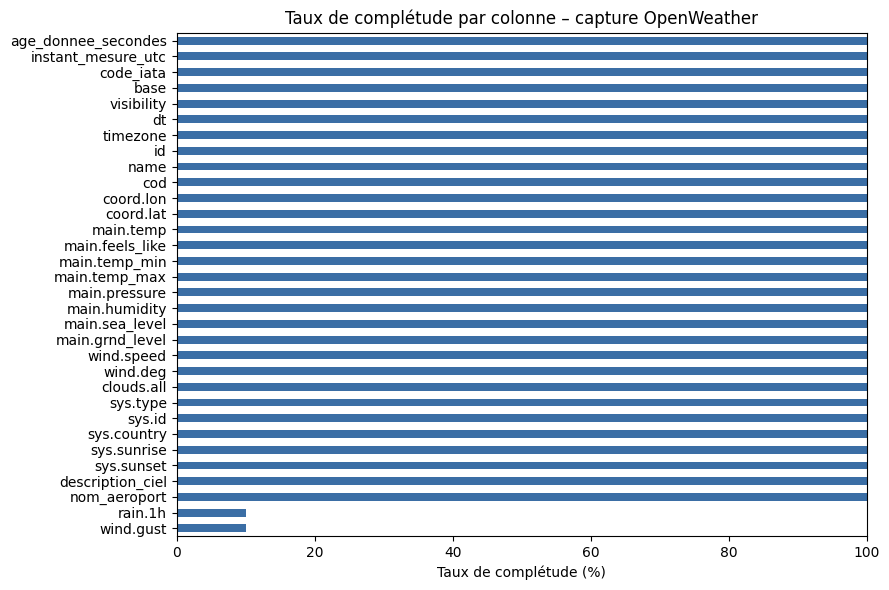

In [8]:
taux_completude = (df_meteo.notna().mean() * 100).sort_values()
print(taux_completude.round(2))

fig, ax = plt.subplots(figsize=(9, 6))
taux_completude.plot(kind="barh", ax=ax, color="#3b6ea5")
ax.set_xlabel("Taux de complétude (%)")
ax.set_title("Taux de complétude par colonne – capture OpenWeather")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

**Observations** : 28 des 30 colonnes sont complètes à 100 %. Seules deux colonnes ont des valeurs manquantes, et dans les deux cas la cause est structurelle plutôt qu'un vrai problème de qualité :

`rain.1h` n'est renseigné que pour Francfort (10 %), seul aéroport où il pleuvait réellement au moment de la capture, et `wind.gust` n'est renseigné que pour Madrid Barajas (10 %), seul aéroport où l'API a mesuré une rafale significative.

OpenWeather n'inclut ces champs dans sa réponse que lorsque le phénomène est présent, au lieu de renvoyer systématiquement une valeur à zéro : l'absence de valeur signifie donc "pas de pluie" ou "pas de rafale notable", pas une donnée manquante à traiter comme une anomalie. C'est le même type de non-complétude structurelle que celle observée sur `baro_altitude` avec OpenSky (liée au statut au sol), à ceci près qu'ici, elle est directement documentée par le comportement de l'API plutôt que déduite par croisement de colonnes.

## 6. Les valeurs sont-elles physiquement cohérentes ?

Je vérifie que chaque variable reste dans des bornes physiquement plausibles : température entre -60 et 55 degrés (records mondiaux), humidité entre 0 et 100 %, pression atmosphérique entre 870 et 1085 hPa (records mondiaux), vitesse du vent positive, et visibilité entre 0 et 10 000 mètres (10 km étant le plafond renvoyé par l'API, qui ne distingue pas au-delà).

In [9]:
nb_temperature_hors_bornes = (
    (df_meteo["main.temp"] < -60) | (df_meteo["main.temp"] > 55)
).sum()
nb_humidite_hors_bornes = (
    (df_meteo["main.humidity"] < 0) | (df_meteo["main.humidity"] > 100)
).sum()
nb_pression_hors_bornes = (
    (df_meteo["main.pressure"] < 870) | (df_meteo["main.pressure"] > 1085)
).sum()
nb_vent_negatif = (df_meteo["wind.speed"] < 0).sum()
nb_visibilite_hors_bornes = (
    (df_meteo["visibility"] < 0) | (df_meteo["visibility"] > 10000)
).sum()

print(f"Températures hors bornes [-60, 55] °C : {nb_temperature_hors_bornes} ligne(s)")
print(f"Humidités hors bornes [0, 100] % : {nb_humidite_hors_bornes} ligne(s)")
print(f"Pressions hors bornes [870, 1085] hPa : {nb_pression_hors_bornes} ligne(s)")
print(f"Vitesses de vent négatives : {nb_vent_negatif} ligne(s)")
print(f"Visibilités hors bornes [0, 10000] m : {nb_visibilite_hors_bornes} ligne(s)")
print()
print("Statistiques descriptives des variables météo principales :")
df_meteo[
    ["main.temp", "main.humidity", "main.pressure", "wind.speed", "visibility"]
].describe()

Températures hors bornes [-60, 55] °C : 0 ligne(s)
Humidités hors bornes [0, 100] % : 0 ligne(s)
Pressions hors bornes [870, 1085] hPa : 0 ligne(s)
Vitesses de vent négatives : 0 ligne(s)
Visibilités hors bornes [0, 10000] m : 0 ligne(s)

Statistiques descriptives des variables météo principales :


,main.temp,main.humidity,main.pressure,wind.speed,visibility
count,10.000000,10.000000,10.000000,10.000000,10.0
mean,24.954000,55.900000,1013.100000,5.130000,10000.0
std,5.627352,19.307166,1.791957,2.499702,0.0
min,16.050000,34.000000,1010.000000,1.540000,10000.0
25%,19.957500,40.500000,1012.000000,2.827500,10000.0
50%,26.510000,49.500000,1013.500000,5.915000,10000.0
75%,27.810000,72.500000,1014.750000,6.560000,10000.0
max,32.300000,88.000000,1015.000000,8.940000,10000.0


**Observations** : aucune valeur hors bornes sur cette capture, pour aucune des cinq variables vérifiées. Les températures vont de 16,05 à 32,30 degrés, l'humidité de 34 à 88 %, la pression de 1010 à 1015 hPa (un intervalle très resserré, cohérent avec une zone de haute pression généralisée sur l'Europe ce jour-là), le vent de 1,54 à 8,94 m/s, et la visibilité est au maximum (10 000 m) pour les dix aéroports.

Ce dernier point est à garder en tête pour la suite : l'API plafonne la visibilité à 10 km, donc cette colonne ne permettra pas de distinguer une bonne visibilité d'une excellente visibilité, seulement de détecter les cas de visibilité réduite (brouillard, tempête) si elle redescend un jour sous ce plafond.

Les bornes ci-dessus supposent une unité pour chaque variable. Le module d'ingestion demande à OpenWeather le système métrique (`units=metric`), ce qui doit donner des degrés Celsius et des mètres par seconde, mais je le vérifie sur les valeurs observées plutôt que sur ce seul paramètre : une température renvoyée en kelvins ou un vent en kilomètres par heure passeraient inaperçus dans un contrôle de bornes mal calibré.

In [10]:
print("Températures observées (main.temp, main.feels_like) :")
print(df_meteo[["main.temp", "main.feels_like"]].describe().round(2))
print()

BORNE_ECHELLE_KELVIN = 200
nb_temperatures_kelvin = (df_meteo["main.temp"] > BORNE_ECHELLE_KELVIN).sum()
print(
    f"Températures supérieures à {BORNE_ECHELLE_KELVIN}, donc lues sur l'échelle Kelvin : "
    f"{nb_temperatures_kelvin} ligne(s)"
)

vent_min = df_meteo["wind.speed"].min()
vent_max = df_meteo["wind.speed"].max()
print(
    f"Vent observé : de {vent_min:.2f} à {vent_max:.2f}, "
    f"soit de {vent_min * 3.6:.1f} à {vent_max * 3.6:.1f} km/h si l'unité est bien le m/s"
)
print(
    f"Pression observée : de {df_meteo['main.pressure'].min()} "
    f"à {df_meteo['main.pressure'].max()} hPa"
)
print(
    f"Visibilité observée : de {df_meteo['visibility'].min()} "
    f"à {df_meteo['visibility'].max()} m"
)

Températures observées (main.temp, main.feels_like) :
       main.temp  main.feels_like
count      10.00            10.00
mean       24.95            25.37
std         5.63             6.49
min        16.05            16.01
25%        19.96            19.76
50%        26.51            26.35
75%        27.81            27.92
max        32.30            36.74

Températures supérieures à 200, donc lues sur l'échelle Kelvin : 0 ligne(s)
Vent observé : de 1.54 à 8.94, soit de 5.5 à 32.2 km/h si l'unité est bien le m/s
Pression observée : de 1010 à 1015 hPa
Visibilité observée : de 10000 à 10000 m


**Observations** : les températures vont de 16,05 à 32,30, alors que les mêmes conditions en kelvins se liraient entre 289 et 305 ; aucune ligne ne dépasse 200, donc l'échelle est bien celle des degrés Celsius.

Le vent va de 1,54 à 8,94, soit de 5,5 à 32,2 km/h une fois lu en mètres par seconde, l'ordre de grandeur d'une brise légère à modérée — cohérent avec les ciels dégagés ou couverts de cette capture.
La même série lue en kilomètres par heure donnerait moins de 9 km/h partout, y compris à Istanbul et Londres qui ressortent nettement comme les plus venteux.

La pression reste entre 1010 et 1015, valeurs typiques d'une pression au niveau de la mer en hectopascals (elle vaudrait environ 101 000 en pascals), et la visibilité s'exprime en mètres avec un plafond à 10 000.


Les unités observées correspondent donc à celles documentées, et ces champs pourront être stockés sans conversion.

Quatre colonnes décrivent la même grandeur sous des angles différents : `main.temp`, la température ressentie `main.feels_like`, et l'encadrement `main.temp_min` / `main.temp_max`. Vérifier chaque colonne dans ses bornes ne suffit pas, il faut aussi qu'elles restent cohérentes entre elles : un ressenti très éloigné de la température mesurée, ou une température sortant de son propre encadrement, trahirait une erreur de collecte ou de mise à plat.

In [11]:
ecart_ressenti = df_meteo["main.feels_like"] - df_meteo["main.temp"]

SEUIL_ECART_RESSENTI = 10
nb_ecarts_suspects = (ecart_ressenti.abs() > SEUIL_ECART_RESSENTI).sum()
masque_encadrement_invalide = (
    (df_meteo["main.temp"] < df_meteo["main.temp_min"])
    | (df_meteo["main.temp"] > df_meteo["main.temp_max"])
)

print("Écart feels_like - temp (degrés) :")
print(ecart_ressenti.describe().round(2))
print()
print(f"Écarts supérieurs à {SEUIL_ECART_RESSENTI} degrés en valeur absolue : {nb_ecarts_suspects} ligne(s)")
print(f"Lignes où temp sort de [temp_min, temp_max] : {masque_encadrement_invalide.sum()}")
print()
print(
    df_meteo[
        ["code_iata", "main.temp", "main.feels_like", "main.temp_min", "main.temp_max", "main.humidity"]
    ].assign(ecart_ressenti=ecart_ressenti.round(2))
)

Écart feels_like - temp (degrés) :
count    10.00
mean      0.42
std       1.82
min      -0.60
25%      -0.31
50%      -0.17
75%      -0.05
max       5.50
dtype: float64

Écarts supérieurs à 10 degrés en valeur absolue : 0 ligne(s)
Lignes où temp sort de [temp_min, temp_max] : 0

  code_iata  main.temp  main.feels_like  main.temp_min  main.temp_max  \
0       CDG      27.87            27.69          26.36          29.17   
1       LHR      25.79            25.47          24.97          27.65   
2       FRA      18.16            18.07          17.76          19.18   
3       AMS      24.99            24.69          23.84          26.10   
4       MAD      27.63            27.23          26.23          28.65   
5       FCO      31.24            36.74          30.12          32.51   
6       IST      27.23            27.99          27.23          27.23   
7       DUB      18.28            18.12          17.62          19.39   
8       MUC      16.05            16.01          16.00        

**Observations** : aucune incohérence. L'écart entre ressenti et température mesurée reste compris entre -0,60 et +5,50 degré, très loin du seuil de 10 degrés que je m'étais fixé, et aucune température ne sort de son encadrement `temp_min` / `temp_max`.

Le seul écart notable, celui de Rome Fiumicino (+5,50), s'explique par le tableau lui-même : 31,24 degrés avec 65 % d'humidité, exactement la combinaison qui fait grimper le ressenti. À l'inverse, Barcelone est plus chaude (32,30) mais avec 34 % d'humidité seulement, et son ressenti est légèrement inférieur à la température mesurée.

Un point de vigilance apparaît au passage : Istanbul est le seul aéroport où `temp_min`, `temp_max` et `temp` sont exactement égaux (27,23), signe que l'API n'y renvoie pas d'amplitude sur la maille concernée. L'encadrement de température n'est donc pas exploitable partout, et ne pourra pas servir de feature à lui seul.

## 7. Quelle est la répartition des conditions météo par aéroport ?

Je compare la température et la vitesse du vent entre les dix hubs, pour voir si des écarts notables apparaissent entre le nord et le sud de l'Europe au moment de cette capture.

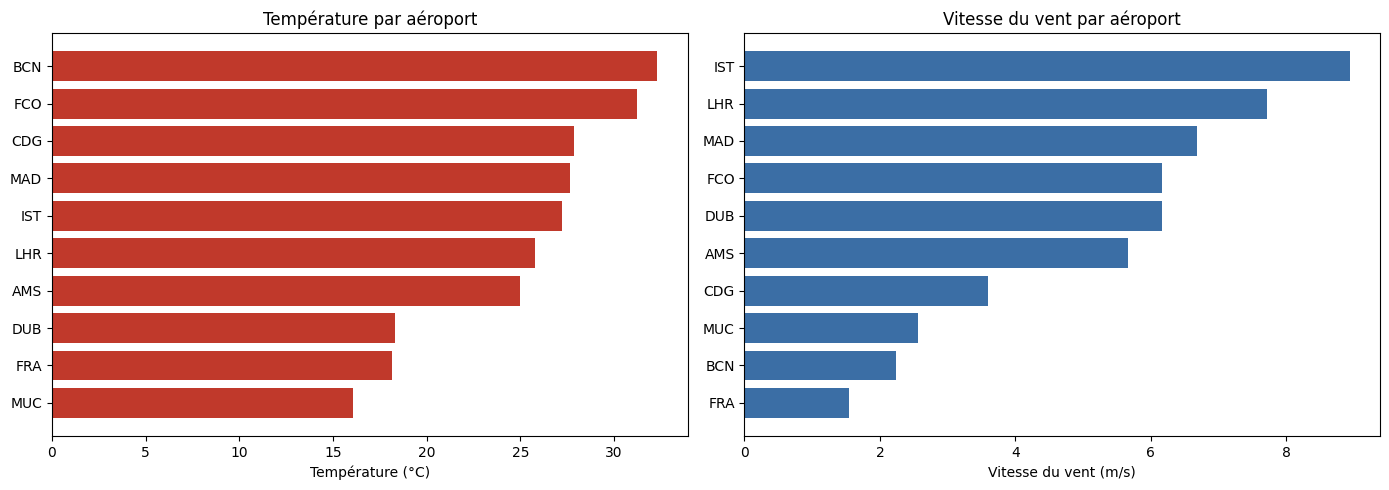

,nom_aeroport,code_iata,description_ciel,main.temp,wind.speed
0,Paris Charles-de-Gaulle,CDG,ciel dégagé,27.87,3.60
1,Londres Heathrow,LHR,ciel dégagé,25.79,7.72
2,Francfort,FRA,légère pluie,18.16,1.54
3,Amsterdam Schiphol,AMS,couvert,24.99,5.66
4,Madrid Barajas,MAD,ciel dégagé,27.63,6.69
5,Rome Fiumicino,FCO,nuageux,31.24,6.17
6,Istanbul,IST,ciel dégagé,27.23,8.94
7,Dublin,DUB,couvert,18.28,6.17
8,Munich,MUC,couvert,16.05,2.57
9,Barcelone,BCN,nuageux,32.30,2.24


In [12]:
df_tri_temperature = df_meteo.sort_values("main.temp", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(df_tri_temperature["code_iata"], df_tri_temperature["main.temp"], color="#c0392b")
axes[0].set_xlabel("Température (°C)")
axes[0].set_title("Température par aéroport")
axes[0].invert_yaxis()

df_tri_vent = df_meteo.sort_values("wind.speed", ascending=False)
axes[1].barh(df_tri_vent["code_iata"], df_tri_vent["wind.speed"], color="#3b6ea5")
axes[1].set_xlabel("Vitesse du vent (m/s)")
axes[1].set_title("Vitesse du vent par aéroport")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

df_meteo[["nom_aeroport", "code_iata", "description_ciel", "main.temp", "wind.speed"]]

**Observations** : un net gradient nord-sud apparaît sur cette capture. Barcelone (32,30°C) et Rome (31,24°C) sont les plus chaudes, suivies d'Istanbul (27,23°C), tandis que Munich (16,05°C) et Francfort (18,16°C) sont les plus fraîches, avec un écart d'environ 16 degrés entre les extrêmes. Le vent ne suit ici aucune logique géographique évidente ni aucun lien avec la température : c'est Istanbul (8,94 m/s) et Londres (7,72 m/s) qui sont les plus venteux, alors que Francfort (1,54 m/s), Barcelone (2,24 m/s, pourtant l'aéroport le plus chaud) et Munich (2,57 m/s) sont les plus calmes.

Ce type d'écart entre aéroports est précisément ce qu'on veut capturer comme feature pour la prédiction de retard : une même compagnie peut décoller sans encombre d'un aéroport calme et subir un retard à l'arrivée sur un aéroport plus venteux ou pluvieux.

## 8. Quels types de données par colonne ?

Je vérifie que les types Python correspondent à ce qu'on attend pour chaque champ.

In [13]:
print("Types de données par colonne :")
print(df_meteo.dtypes)

Types de données par colonne :
nom_aeroport                        object
code_iata                           object
base                                object
visibility                           int64
dt                                   int64
timezone                             int64
id                                   int64
name                                object
cod                                  int64
coord.lon                          float64
coord.lat                          float64
main.temp                          float64
main.feels_like                    float64
main.temp_min                      float64
main.temp_max                      float64
main.pressure                        int64
main.humidity                        int64
main.sea_level                       int64
main.grnd_level                      int64
wind.speed                         float64
wind.deg                             int64
clouds.all                           int64
sys.type               

**Observations** : les types sont cohérents avec ce qu'on attend, avec un mélange d'`int64` (identifiants, angles, codes) et de `float64` (température, vent, pluie) qui reflète simplement la précision renvoyée par l'API pour chaque champ, plus quelques colonnes `object` pour le texte (`name`, `description_ciel`, `sys.country`) et une colonne `datetime64[ns, UTC]` pour l'horodatage de mesure que j'ai calculé moi-même. Rien d'aberrant à signaler ici.

## 9. Quel volume de données cela représente-t-il ?

Je calcule la taille du fichier JSON de cette capture (dix aéroports), puis je la compare à celle d'OpenSky, avant de projeter le volume total sur la durée du projet selon différentes fréquences de collecte.

In [14]:
taille_octets = os.path.getsize(chemin_fichier)
taille_ko = taille_octets / 1024

print(f"Nombre de lignes de cette capture : {len(df_meteo)}")
print(f"Taille du fichier JSON brut : {taille_octets} octets ({taille_ko:.1f} Ko)")
print()

DUREE_COLLECTE_JOURS = 14
print("Projection sur deux semaines de collecte, selon la fréquence choisie :")
for frequence_minutes in (10, 30, 60):
    nb_captures = DUREE_COLLECTE_JOURS * 24 * 60 / frequence_minutes
    volume_total_mo = nb_captures * taille_octets / (1024 * 1024)
    print(
        f"  - Toutes les {frequence_minutes} min : {nb_captures:.0f} captures, "
        f"environ {volume_total_mo:.2f} Mo au total"
    )

Nombre de lignes de cette capture : 10
Taille du fichier JSON brut : 11458 octets (11.2 Ko)

Projection sur deux semaines de collecte, selon la fréquence choisie :
  - Toutes les 10 min : 2016 captures, environ 22.03 Mo au total
  - Toutes les 30 min : 672 captures, environ 7.34 Mo au total
  - Toutes les 60 min : 336 captures, environ 3.67 Mo au total


**Observations** : une capture pour les dix hubs pèse 11,2 Ko, sans commune mesure avec le mégaoctet d'une capture OpenSky sur toute l'Europe. Sur deux semaines, même une collecte toutes les 10 minutes (le rythme de rafraîchissement réel des données OpenWeather, donc la fréquence la plus fine qui ait un intérêt) ne représenterait qu'environ 22 Mo, contre plusieurs gigaoctets pour OpenSky à fréquence comparable.

Cet écart s'explique directement par la différence d'architecture des deux API : OpenSky renvoie des milliers de lignes par appel (tous les avions d'une zone), OpenWeather en renvoie une seule par appel (un point précis) multipliée par le nombre de hubs suivis.

La contrainte sur cette source n'est donc pas le volume de stockage, mais le nombre d'appels HTTP à effectuer si on voulait suivre davantage d'aéroports.

## 10. Rapport de profiling automatisé (ydata-profiling)

Comme pour OpenSky, je complète cette exploration ciblée par un rapport `ydata-profiling` exhaustif, qui couvre systématiquement chaque colonne. Avec seulement dix lignes, ce rapport a surtout une valeur de vérification structurelle (types, complétude) plutôt que statistique (les distributions et corrélations calculées sur dix points ont peu de portée) : c'est une conséquence directe de l'architecture point par point d'OpenWeather, à la différence d'OpenSky qui renvoie plusieurs milliers de lignes par capture.

In [15]:
from ydata_profiling import ProfileReport

DOSSIER_PROFILING = os.path.join(RACINE_PROJET, "data", "profiling_reports")
os.makedirs(DOSSIER_PROFILING, exist_ok=True)
chemin_rapport = os.path.join(DOSSIER_PROFILING, "openweather_profiling_report.html")

warnings.filterwarnings("ignore", category=FutureWarning, module="ydata_profiling")

rapport = ProfileReport(
    df_meteo,
    title="Rapport de profiling - OpenWeather",
    explorative=True,
    progress_bar=False,
)
rapport.to_file(chemin_rapport)

print(f"Rapport de profiling généré : {chemin_relatif_projet(chemin_rapport)}")

## 11. Synthèse et conclusions

**Complétude générale** : sur cette capture, 28 des 30 champs sont complets à 100 %. Les deux seuls champs avec des valeurs manquantes (`rain.1h`, `wind.gust`) sont structurellement absents quand le phénomène correspondant n'est pas mesuré, exactement comme OpenWeather le documente : rien à traiter comme une anomalie, seulement une règle de nettoyage à prévoir (remplacer l'absence par zéro plutôt que par une valeur indéterminée).

**Anomalies repérées** : aucune. Les cinq variables vérifiées (température, humidité, pression, vent, visibilité) restent toutes dans des bornes physiquement plausibles sur cette capture. Un point de vigilance identifié plutôt qu'une anomalie : la visibilité est plafonnée à 10 000 mètres pour les dix aéroports, ce qui limite la capacité de cette colonne à distinguer les bonnes conditions entre elles, mais reste utile pour détecter une dégradation en dessous de ce plafond.

**Fraîcheur** : sur cette capture, les mesures ont entre 1,3 et 7,3 secondes d'écart avec l'instant de la requête, un délai très court et homogène d'un aéroport à l'autre, plus fin que le cycle de rafraîchissement d'environ 10 minutes annoncé par OpenWeather pour les données courantes (une capture précédente avait toutefois montré un délai ponctuellement plus élevé, de l'ordre de quelques minutes, pour certains aéroports : à surveiller sur davantage de captures). Contrairement à OpenSky, il n'y a pas ici de risque de récupérer une donnée vieille de plusieurs heures.

**Volumétrie** : une capture des dix hubs pèse 11,2 Ko, plusieurs ordres de grandeur en dessous d'une capture OpenSky. Cette différence n'est pas un hasard mais une conséquence directe de l'architecture des deux API (zone géographique contre point géographique), à garder en tête pour dimensionner la fréquence de collecte du pipeline final.

**Conclusions pour la suite du projet** : la structure obtenue (une ligne par aéroport et par capture, avec température, vent, pluie, pression et description du ciel) est directement exploitable comme dimension météo dans le futur schéma en étoile. Les règles de nettoyage à prévoir en Phase 2 sont désormais claires : remplacer l'absence de `rain.1h` et `wind.gust` par zéro, retirer la colonne `weather` brute au profit de `description_ciel`, et documenter le plafond de visibilité à 10 km.

Contrairement à OpenSky, la fraîcheur et la cohérence des valeurs ne posent pas de difficulté particulière sur cette source ; le point d'attention principal reste la faible volumétrie par capture, qui suppose de multiplier les collectes dans le temps pour construire un historique météo réellement exploitable par aéroport.

## 12. Nettoyage appliqué sur cette capture

Comme pour OpenSky, je passe maintenant de règles documentées à un nettoyage réellement exécuté sur `df_meteo` : le remplacement par zéro de l'absence structurelle de `rain.1h` et `wind.gust` (l'absence signifiant "phénomène non mesuré", pas une valeur inconnue), et un plafonnement défensif de `visibility` à 10 000 mètres pour rendre explicite dans le code le plafond documenté par l'API, même si aucune valeur ne le dépasse sur cette capture précise.

In [16]:
nb_non_nuls_avant = df_meteo[["rain.1h", "wind.gust"]].notna().sum()

df_meteo_nettoye = df_meteo.copy()
df_meteo_nettoye["rain.1h"] = df_meteo_nettoye["rain.1h"].fillna(0)
df_meteo_nettoye["wind.gust"] = df_meteo_nettoye["wind.gust"].fillna(0)

PLAFOND_VISIBILITE_M = 10000
nb_visibilite_plafonnees = int((df_meteo_nettoye["visibility"] > PLAFOND_VISIBILITE_M).sum())
df_meteo_nettoye["visibility"] = df_meteo_nettoye["visibility"].clip(upper=PLAFOND_VISIBILITE_M)

nb_non_nuls_apres = df_meteo_nettoye[["rain.1h", "wind.gust"]].notna().sum()

print("Valeurs non manquantes avant nettoyage :")
print(nb_non_nuls_avant)
print()
print("Valeurs non manquantes après nettoyage :")
print(nb_non_nuls_apres)
print()
print(f"Valeurs de visibilité plafonnées à {PLAFOND_VISIBILITE_M} m : {nb_visibilite_plafonnees}")

Valeurs non manquantes avant nettoyage :
rain.1h      1
wind.gust    1
dtype: int64

Valeurs non manquantes après nettoyage :
rain.1h      10
wind.gust    10
dtype: int64

Valeurs de visibilité plafonnées à 10000 m : 0


**Observations** : avant nettoyage, `rain.1h` et `wind.gust` n'étaient renseignés que pour 1 aéroport sur 10 chacun (celui où il pleuvait réellement, celui où une rafale a été mesurée) ; après remplacement de l'absence par zéro, les deux colonnes passent à 10/10 valeurs non nulles dans `df_meteo_nettoye`, ce qui les rend directement utilisables comme features numériques sans traitement conditionnel supplémentaire.

Le plafonnement de `visibility` ne modifie aucune valeur sur cette capture (0 valeur au-delà de 10 000 m, les dix aéroports y étant déjà exactement), mais rend la règle explicite dans le code plutôt que seulement documentée en texte, en anticipation d'une future capture avec brouillard ou tempête localisée.